# Rapport : moteur d'analyse de logs

Projet final de Python, ING3.

Auteurs : Benjamin Boyer, Gabriel Guery, Ismail Yacoub et Ilyan Lalmassi.

Ce rapport montre le fonctionnement de notre programme sur le jeu de test du
dossier `data`. Tout le traitement est écrit dans le package `logstream` : ici,
on se contente de l'appeler et d'afficher les résultats.

## Environnement

Le projet tourne dans un environnement virtuel et ses dépendances sont listées
dans `requirements.txt`, généré avec `pip freeze`.

In [1]:
import sys
from collections import defaultdict
from itertools import islice
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt

# Le notebook est dans notebooks/ : on ajoute la racine du projet au chemin.
sys.path.insert(0, str(Path.cwd().parent))

print("Python :", sys.version.split()[0])
print("Environnement virtuel :", sys.prefix != sys.base_prefix)

Python : 3.13.5
Environnement virtuel : True


## Module 1 : lecture des fichiers

`read_log_file` est un générateur : l'appeler ne lit rien, il donne les lignes
une par une quand on les demande. `read_log_sources` enchaîne plusieurs
fichiers avec `yield from`.

On voit ci-dessous que le générateur ne pèse que quelques centaines d'octets,
alors que le fichier en fait plusieurs centaines de milliers.

In [2]:
from logstream.config import BLACKLIST_FILE, DATA_DIR, DEFAULT_LOG_FILES
from logstream.ingestion import load_blacklist, read_log_file, read_log_sources

fichiers = [DATA_DIR / nom for nom in DEFAULT_LOG_FILES]

lignes = read_log_file(fichiers[0])
print("Type :", type(lignes).__name__)
print("Taille du générateur :", sys.getsizeof(lignes), "octets")
print("Taille du fichier :", fichiers[0].stat().st_size, "octets")
print("Première ligne :", next(lignes))
lignes.close()  # on ferme le fichier

total = sum(1 for _ in read_log_sources(fichiers))
print("Lignes dans les 3 fichiers :", total)

Type : generator
Taille du générateur : 240 octets
Taille du fichier : 619249 octets
Première ligne : 2026-10-20T06:00:01 | INFO | 192.168.1.25:443/TCP | user008 | {"method": "GET", "path": "/index.html", "status": 200}
Lignes dans les 3 fichiers : 15225


Chaque ligne est ensuite transformée en dictionnaire. L'horodatage devient
un `datetime` et la source un tuple immuable `(IP, Port, Protocole)`.

In [3]:
from logstream.parsing import parse_text_line

log = parse_text_line(
    '2026-10-20T08:15:32 | WARNING | 203.0.113.7:22/SSH | root | '
    '{"event": "login", "status": "failed"}'
)
pprint(log, sort_dicts=False)

{'timestamp': datetime.datetime(2026, 10, 20, 8, 15, 32),
 'level': 'WARNING',
 'source': ('203.0.113.7', 22, 'SSH'),
 'ip': '203.0.113.7',
 'user_id': 'root',
 'payload': {'event': 'login', 'status': 'failed'},
 'category': 'AUTH',
 'origin_format': 'raw',
 'message': ''}


## Module 2 : pipeline de transformation

`route_entry` utilise un `match-case` pour reconnaître le format de chaque
entrée : chaîne brute, dictionnaire ou tuple de connexion. Une entrée illisible
donne `None`, sans faire planter le programme.

In [4]:
from logstream.pipeline import build_pipeline, route_entry

exemples = [
    "2026-10-20T08:00:00 | INFO | 10.0.0.2:443/TCP | bob | Service démarré",
    {"timestamp": "2026-10-20T08:00:05", "level": "ERROR", "code": 503,
     "ip": "10.0.0.3"},
    ("2026-10-20T08:00:10", "203.0.113.66", 3389, "TCP"),
    "ligne corrompue",
    12345,
]
for exemple in exemples:
    resultat = route_entry(exemple)
    print(type(exemple).__name__, ":",
          resultat["category"] if resultat else "rejetée")

str : SYSTEM
dict : HTTP
tuple : NETWORK
str : rejetée
int : rejetée


`build_pipeline` enchaîne des `map()` et des `filter()`. Ces fonctions sont
paresseuses : les compteurs restent vides tant qu'on n'a pas parcouru le
pipeline.

In [5]:
metriques = defaultdict(int)
pipeline = build_pipeline(read_log_sources(fichiers), metriques)
print("Avant le parcours :", dict(metriques))

for log in islice(pipeline, 3):
    print(log["message"])

for _ in pipeline:  # on parcourt le reste du flux
    pass
print("Après le parcours :", dict(metriques))
print("Entrées rejetées :",
      metriques["non_empty_entries"] - metriques["valid_records"])

Avant le parcours : {}
[2026-10-20 06:00:01] INFO     192.168.1.25:443/TCP user008 (HTTP) GET /index.html (statut 200)
[2026-10-20 06:00:04] ERROR    198.51.100.99:443/TCP user020 (HTTP) code 504 : Erreur serveur HTTP 504
[2026-10-20 06:00:23] INFO     192.168.1.10:80/TCP user025 (HTTP) GET /dashboard (statut 200)
Après le parcours : {'raw_entries': 15225, 'non_empty_entries': 15137, 'parsed_records': 15036, 'valid_records': 15006}
Entrées rejetées : 131


## Module 3 : statistiques et détection

Un seul parcours suffit à remplir les compteurs. Ce sont des `defaultdict(int)` :
demander une clé jamais vue renvoie 0 au lieu de lever une `KeyError`.

Niveau jamais vu : 0
IP actives : 46
IP en erreur : 14


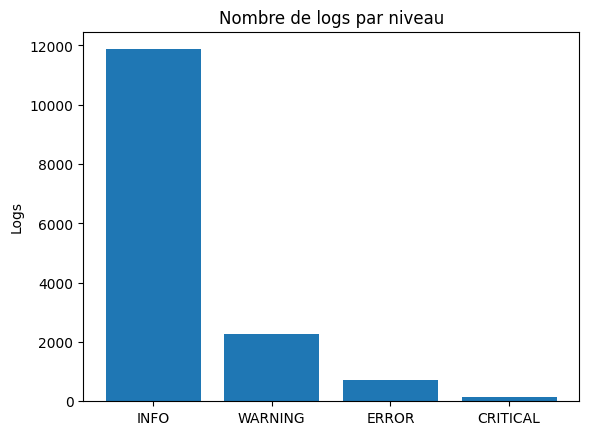

In [6]:
from logstream.aggregation import collect_statistics, compare_ip_sets
from logstream.config import SEVERITY_ORDER

stats = collect_statistics(build_pipeline(read_log_sources(fichiers)))
print("Niveau jamais vu :", stats.by_level["DEBUG"])
print("IP actives :", len(stats.active_ips))
print("IP en erreur :", len(stats.error_ips))

plt.bar(SEVERITY_ORDER, [stats.by_level[n] for n in SEVERITY_ORDER])
plt.title("Nombre de logs par niveau")
plt.ylabel("Logs")
plt.show()

On compare les IP actives (un `set`) à la liste noire (un `frozenset`) avec
les opérateurs `|`, `&`, `-` et `^`.

In [7]:
liste_noire = load_blacklist(BLACKLIST_FILE)

for nom, ips in compare_ip_sets(stats.active_ips, liste_noire).items():
    print(f"{nom:<24} {len(ips):>3} IP")

union                     48 IP
intersection               3 IP
active_not_blacklisted    43 IP
blacklisted_inactive       2 IP
symmetric_difference      45 IP


Pour la force brute, une boucle `while` découpe le flux en lots et une boucle
`for` parcourt chaque lot. Une IP est signalée après 5 échecs consécutifs avec
moins de 5 minutes entre deux échecs.

Le `else` de la boucle `while` ne s'exécute que si aucun `break` n'a eu lieu.
On le voit en limitant le nombre d'alertes : l'analyse n'est alors plus
complète.

Limite de 3 alertes atteinte


Analyse complète : True
Attaques détectées : 70
    198.51.100.23 : 5 échecs en 12s sur user001
    198.51.100.23 : 5 échecs en 11s sur backup
    198.51.100.99 : 5 échecs en 11s sur admin



Avec max_alerts=3, analyse complète : False


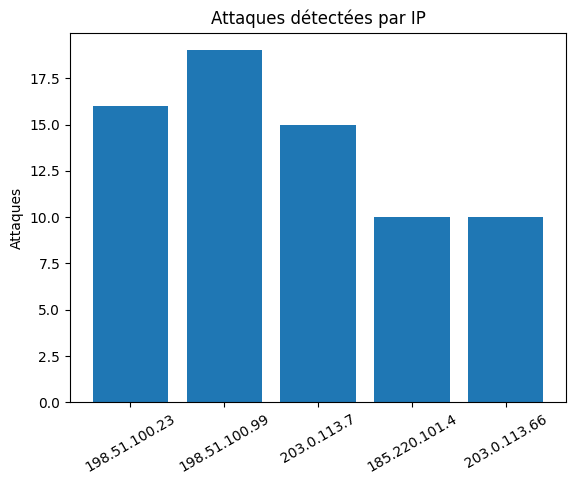

In [8]:
from logstream.detection import detect_brute_force

resultat = detect_brute_force(build_pipeline(read_log_sources(fichiers)))
print("Analyse complète :", resultat.complete)
print("Attaques détectées :", len(resultat.alerts))
for alerte in resultat.alerts[:3]:
    print(" ", alerte)

limite = detect_brute_force(build_pipeline(read_log_sources(fichiers)),
                            max_alerts=3)
print("\nAvec max_alerts=3, analyse complète :", limite.complete)

attaques = defaultdict(int)
for alerte in resultat.alerts:
    attaques[alerte.ip] += 1

plt.bar(list(attaques), list(attaques.values()))
plt.title("Attaques détectées par IP")
plt.ylabel("Attaques")
plt.xticks(rotation=30)
plt.show()

## Module 4 : règles et audit

`apply_security_rules(*args, **kwargs)` reçoit les règles dans `*args` et les
options dans `**kwargs`. Une règle est une simple fonction : on peut donc en
écrire une nouvelle ici et la passer au moteur.

Logs contrôlés : 15006
Alertes : 1956


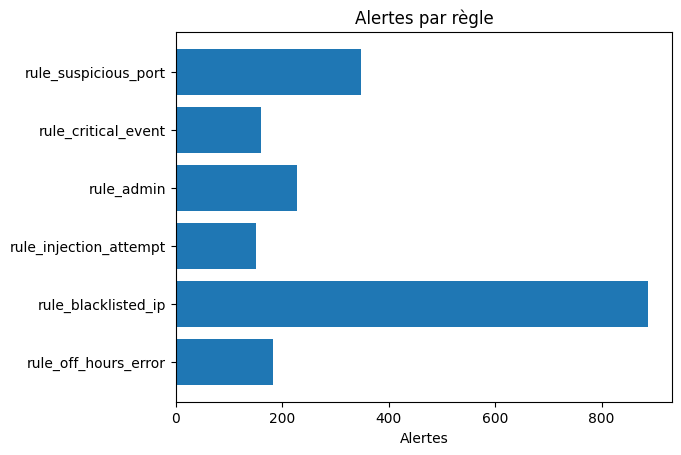

In [9]:
from logstream.rules import apply_security_rules, available_rules


def rule_admin(record, **config):
    if record["user_id"] == "admin":
        return "Compte admin ciblé"
    return None


rapport = apply_security_rules(
    *available_rules().values(), rule_admin,
    records=build_pipeline(read_log_sources(fichiers)),
    blacklist=liste_noire,
)
print("Logs contrôlés :", rapport.records_checked)
print("Alertes :", rapport.total_hits)

plt.barh(list(rapport.hits_by_rule), list(rapport.hits_by_rule.values()))
plt.title("Alertes par règle")
plt.xlabel("Alertes")
plt.show()

L'audit reçoit le résultat de `globals()` ou de `locals()` et décrit chaque
variable. `main.py` fait la même chose et écrit le résultat dans
`output/audit_report.json`.

In [10]:
from logstream.audit import build_audit_report


def exemple_audit():
    seuil = 5
    ips = {"203.0.113.7", "198.51.100.99"}
    flux = build_pipeline(read_log_sources(fichiers))
    return build_audit_report(locales=locals())


variables = exemple_audit()["scopes"]["locales"]["variables"]
for nom, infos in variables.items():
    print(f"{nom:<6} {infos['type']:<10} {infos['size_bytes']} octets")

flux   generator  232 octets
ips    set        216 octets
seuil  int        28 octets


## Mesure de la mémoire

On compare deux approches avec `tracemalloc` sur des fichiers de plus en plus
gros : tout stocker dans une liste, ou traiter les lignes avec le pipeline.

2000 lignes : liste 2076 Kio, pipeline 40 Kio


5000 lignes : liste 5193 Kio, pipeline 42 Kio


10000 lignes : liste 10509 Kio, pipeline 46 Kio


20000 lignes : liste 21128 Kio, pipeline 50 Kio


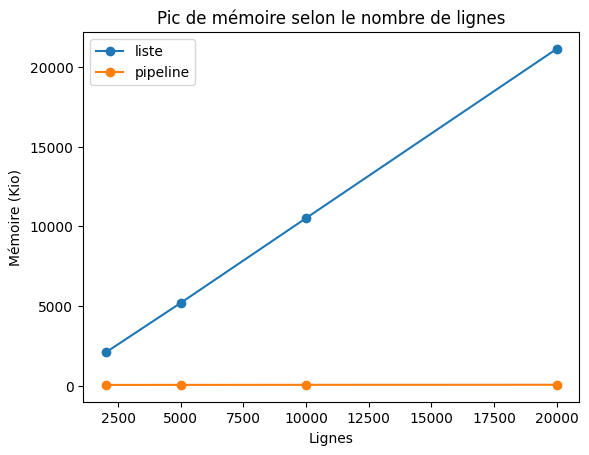

In [11]:
import tempfile
import tracemalloc

from logstream.simulator import generate_auth_lines, write_lines


def pic_memoire(fonction):
    tracemalloc.start()
    fonction()
    _, pic = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pic / 1024  # en Kio


tailles = [2000, 5000, 10000, 20000]
avec_liste = []
avec_pipeline = []

with tempfile.TemporaryDirectory() as dossier:
    for taille in tailles:
        chemin = Path(dossier) / "auth.log"
        write_lines(chemin, generate_auth_lines(taille))
        flux = lambda: build_pipeline(read_log_file(chemin))
        avec_liste.append(pic_memoire(lambda: list(flux())))
        avec_pipeline.append(
            pic_memoire(lambda: collect_statistics(flux())))
        print(f"{taille} lignes : liste {avec_liste[-1]:.0f} Kio, "
              f"pipeline {avec_pipeline[-1]:.0f} Kio")

plt.plot(tailles, avec_liste, marker="o", label="liste")
plt.plot(tailles, avec_pipeline, marker="o", label="pipeline")
plt.title("Pic de mémoire selon le nombre de lignes")
plt.xlabel("Lignes")
plt.ylabel("Mémoire (Kio)")
plt.legend()
plt.show()

Avec la liste, la mémoire augmente avec le nombre de lignes. Avec le
pipeline, elle reste quasiment stable, car on ne garde que les compteurs et les
IP distinctes. Sur le programme complet (`main.py`), le pic passe d'environ
1,2 Mo pour 15 000 lignes à 2,1 Mo pour 457 000 lignes.

## Bilan

Tous les points du cahier des charges sont traités :

- module 1 : générateurs avec `yield` et `yield from`, dictionnaires et tuples ;
- module 2 : `map()`, `filter()`, lambdas, f-strings et `match-case` ;
- module 3 : `set`, `frozenset`, `defaultdict`, boucles `while` et `for` avec
  `break`, `continue` et `else` ;
- module 4 : `apply_security_rules(*args, **kwargs)`, `globals()` et `locals()`.

Notre programme a quelques limites. Les fichiers sont lus l'un après l'autre,
sans tri par date, et chaque analyse relit les données, ce qui prend du temps
sur de très gros volumes. Les règles d'injection cherchent seulement des
morceaux de texte connus.

Ce projet nous a surtout appris à penser en flux : au lieu de charger les
données puis de les traiter, on décrit une suite d'étapes que chaque ligne
traverse.